# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

---

## Recap from H1: what you committed to

Paste (or rewrite in your own words) your H1 problem definition and scope contract here. This anchors H2: the implementation, experiments, and report that follow must deliver against this scope. If you've pivoted since H1, note the pivot and the reason; your tutor will read this before the H3 interview.

**Problem (from H1):** Numerous online job boards are flooded with fraudulent and fake postings which are designed to
collect personal information such as IC/passport numbers, bank details or extracting training, visa,
or processing fees from applicants. These scams are deliberately written to look like genuine ads,
so they are hard to spot with the naked eye, and an individual job-seeker may scroll multiple job
postings in a day. The harm affects students and fresh graduates the most, who are inexperienced,
eager, or even desperate are the most likely group to be targeted. My project addresses one specific
part of this problem: given the text and metadata of a single job posting, automatically classify it as
genuine or fraudulent and explain the reasons for the decision, so an applicant can choose to judge a
posting before giving any personal details or money. Im deliberately not trying to detect every scam
everywhere, but only to make a reliable, explainable genuine vs fraud judgement on English language
only postings.

**Technique(s) (from H1):** My system combines three FIT1061 techniques into one pipeline:
1. Classification: Multinomial Naive Bayes. Each posting’s title and description are lowercased,
split into words, and counted over a vocabulary built from the training set only. The classifier
learns P(word | fake) and P(word | genuine) with Laplace smoothing. It outputs P(fake | posting)
a value from 0 to 1.
2. Weighted sums scoring: A risk score combines the Naive Bayes probability with red-flag features,
an example: risk = w_1 * P(fake) + w_2 * (no company logo) + w_3 * (no screening questions) + w_4 * (mentions a payment term). A posting is then flagged as ”needs review” if risk >= threshold t.
3. Hill climbing: To tune the weights and threshold, I search for the values (w_1, w_2, w_3, w_4, t) that give the best F1 on the validation set. Starting from equal weights, I change one value by +/-0.05 at a time and keep the change only if F1 improves. The search stops when no change helps. I use hill climbing because F1 changes in jumps rather than smoothly, so there is no gradient to follow, but hill climbing only needs to compare scores.

**Data (from H1):** I will use the Real/Fake Job Posting Prediction dataset on Kaggle, which is based on the Employment Scam Aegean Dataset (EMSCAD) published by Shivam Bansal based on data by The University of the Aegean Laboratory of Information & Communication Systems Security. The dataset contains 17880 job postings, each labeled 0 for genuine or 1 for fraudulent which is the target. Each has text like title, description, requirements, company profile, benefits, and
structured fields including three yes/no flags like telecommuting, has_company_logo, has_questions.
For training and testing, my inputs will be words taken from the text together with the yes/no flags, and the label is fraudulent. Its a standard labelled classification dataset, which is exactly what Naive Bayes needs which are the title and description.

**What makes this HD-level (from H1):** First, the data is heavily imbalanced: only about 4.8% of postings are fake, so a model that calls everything genuine would score about 95% accuracy but catch no scams. I therefore judge it on fake-class recall and F1 and compare it against a majority-class baseline and a keyword-rule baseline. Second, it combines three techniques into one system instead of using one on its own: a hand-coded Naive Bayes classifier, a weighted risk score that adds red-flag features, and hill climbing to tune that score. Third, every flagged posting comes with the top words and red flags behind the decision, so users can see why it was flagged. Finally, I check fairness by comparing false-alarm rates for postings with and without a company logo, so honest small employers are not unfairly flagged.

**Pivot since H1 (if any):** No change to the approach or targets. I removed 2,093 duplicate postings (193 fake) before splitting, so the same posting cannot appear in both training and testing, and I added a no-logo baseline as a stronger comparison than the keyword rule. After the first test run, I also tested length-normalised Naive Bayes (Experiment 3) on validation and ran a clearly labelled second test run, keeping the first run as the official result.

### Setup
Imports, a fixed random seed (42) for reproducibility, and project settings. Naive Bayes uses only title and description (as scoped in H1). The three 0/1 flags feed the weighted risk score. Library versions are printed so the results can be reproduced.

- re is for splitting text into words and finding payment phrases like "registration fee".
- Counter is for counting words for Naive Bayes, which I will code by hand.
- pandas is for loading the CSV and working with the table

In [2]:
# --- SETUP ---
import re
from collections import Counter
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# Project settings
DATA_PATH = "fake_job_postings.csv"
TEXT_COLS = ["title", "description"]
FLAG_COLS = ["has_company_logo", "has_questions", "telecommuting"]
LABEL = "fraudulent"

print("Setup OK.")
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", plt.matplotlib.__version__)

Setup OK.
numpy 2.5.1 | pandas 3.1.0 | matplotlib 3.11.1


### Data

**Step 1:** load and check the data

In [3]:
# --- DATA LOAD ---
def load_postings(path):
    """Load the CSV and check if it contains the columns and labels the project needs"""
    df = pd.read_csv(path)
    missing = [c for c in TEXT_COLS + FLAG_COLS + [LABEL] if c not in df.columns]
    assert not missing, f"Missing expected columns: {missing}"
    assert set(df[LABEL].unique()) <= {0, 1}, "Label must be 0 (genuine) or 1 (fake)"
    return df

df = load_postings(DATA_PATH)
print("Shape: ", df.shape)
print(df[LABEL].value_counts())
print(f"Amount of fake jobs: {df[LABEL].mean():.2%}")

Shape:  (17880, 18)
fraudulent
0    17014
1      866
Name: count, dtype: int64
Amount of fake jobs: 4.84%


The raw dataset matches my H1, 17880 postings, 18 columns, and 866 fake postings. Because only about 1 in 20 postings is fake, accuracy alone would be misleading, so evaluate on fake class recall and F1

**Step 2:** check for any missing values or duplicates

In [4]:
# --- DATA QUALITY CHECKS ---
def missing_report(df):
    """The amount of empty values per column, sorted by the worst first"""
    return df.isna().mean().sort_values(ascending=False).round(3)

print("Missing values per column:")
print(missing_report(df))

duplicates = df.duplicated(subset=TEXT_COLS)
print("\nDuplicate postings where there is same title and description:", duplicates.sum())
print("Of which that are fake:", df.loc[duplicates, LABEL].sum())

Missing values per column:
salary_range           0.840
department             0.646
required_education     0.453
benefits               0.403
required_experience    0.394
function               0.361
industry               0.274
employment_type        0.194
company_profile        0.185
requirements           0.151
location               0.019
description            0.000
job_id                 0.000
telecommuting          0.000
has_questions          0.000
has_company_logo       0.000
title                  0.000
fraudulent             0.000
dtype: float64

Duplicate postings where there is same title and description: 2093
Of which that are fake: 193


**Step 2b:** remove duplicate job postings

In [5]:
def remove_duplicates(df, cols):
    """Remove any repeated postings to prevent data leakage"""
    conflicts = df.groupby(cols, dropna=False)[LABEL].nunique()
    print("Duplicate groups with conflicting labels:", (conflicts > 1).sum())
    return df.drop_duplicates(subset=cols, keep="first").reset_index(drop=True)

before = len(df)
df = remove_duplicates(df, TEXT_COLS)
print(f"Removed {before - len(df)} duplicates -> {len(df)} rows | {df[LABEL].sum()} fake | {df[LABEL].mean():.2%}")

Duplicate groups with conflicting labels: 0
Removed 2093 duplicates -> 15787 rows | 673 fake | 4.26%


**Step 3:** combine the text and handle the missing fields

In [6]:
# --- DATA: BUILD TEXT ---
def build_text(df):
    """Join title and description"""
    return df[TEXT_COLS].fillna("").apply(lambda row: " ".join(row), axis=1).str.strip()

df["text"] = build_text(df)
print("Postings with no text:", (df["text"].str.len() == 0).sum())
print("\nWords per posting:")
print(df["text"].str.split().str.len().describe().round(1))

Postings with no text: 0

Words per posting:
count    15787.0
mean       180.2
std        123.0
min          2.0
25%         97.5
50%        154.0
75%        234.0
max       2118.0
Name: text, dtype: float64


**Step 4:** stratified 70/15/15 split

In [7]:
# --- DATA: STRATIFIED SPLIT ---
def stratified_split(df, label, fractions=(0.70, 0.15, 0.15), seed=SEED):
    """Split each class separately so that every part keeps the 4.26% of fake jobs"""
    assert abs(sum(fractions) - 1.0) < 1e-9
    rng = np.random.default_rng(seed)
    parts = {"train": [], "val": [], "test": []}
    for cls in sorted(df[label].unique()):
        index = rng.permutation(df.index[df[label] == cls].to_numpy())
        n_train = int(round(fractions[0] * len(index)))
        n_val = int(round(fractions[1] * len(index)))
        parts["train"] += list(index[:n_train])
        parts["val"] += list(index[n_train:n_train + n_val])
        parts["test"] += list(index[n_train + n_val:])
    return {k: df.loc[v].sample(frac=1, random_state=seed) for k, v in parts.items()}

splits = stratified_split(df, LABEL)
train, val, test = splits["train"], splits["val"], splits["test"]

for name, part in splits.items():
    print(f"{name:5s}: {len(part):5d} rows | {part[LABEL].sum():3d} fake | {part[LABEL].mean():.2%}")

assert len(train) + len(val) + len(test) == len(df)
assert not set(train.index) & set(val.index)
assert not set(train.index) & set(test.index)
assert not set(val.index) & set(test.index)
print("Split checks passed.")

train: 11051 rows | 471 fake | 4.26%
val  :  2368 rows | 101 fake | 4.27%
test :  2368 rows | 101 fake | 4.27%
Split checks passed.


The test set is not used until the final evaluation, because all tuning is done on the validation set only.

### Implementation

**Step 1:** Tokeniser

In [8]:
# --- IMPLEMENTATION: TOKENISER ---

PLACEHOLDER = re.compile(r"#(url|email|phone)_[^#]*#", re.IGNORECASE)
WORD = re.compile(r"[a-z]+")

def tokenise(text):
    text = PLACEHOLDER.sub(lambda m: f" {m.group(1).lower()}token ", text)
    return WORD.findall(text.lower())

#tests
assert tokenise("Earn $1000 a day! Visit #URL_abc123#") == ["earn", "a", "day", "visit", "urltoken"]
assert tokenise("") == []
assert tokenise("HELLO hello") == ["hello", "hello"]
print("Tokeniser tests all passed!")

for part in (train, val, test):
    part["tokens"] = part["text"].apply(tokenise)

is_fake = train[LABEL] == 1
for tok in ["urltoken", "emailtoken", "phonetoken"]:
    has = train["tokens"].apply(lambda t: tok in t)
    print(f"{tok:10s}: {has[is_fake].mean():.1%} of fake vs {has[~is_fake].mean():.1%} of genuine")

Tokeniser tests all passed!
urltoken  : 26.3% of fake vs 14.4% of genuine
emailtoken: 5.5% of fake vs 2.8% of genuine
phonetoken: 3.8% of fake vs 1.4% of genuine


The tokeniser lowercases text and keeps only letters. The dataset anonymises links, emails and phone numbers as random codes (e.g. #URL_8f3a...#), so I turn each one into a single token (urltoken, emailtoken, phonetoken) instead of letting it split into meaningless fragments. This lets Naive Bayes learn from them as features. In the training set, fake postings contain them noticeably more often: links 26.3% vs 14.4%, emails 5.5% vs 2.8%, and phone numbers 3.8% vs 1.4%. This fits a common scam pattern of moving applicants off the job site to a private link, email or phone number.

**Step 2:** Vocabulary

In [9]:
# --- IMPLEMENTATION: VOCABULARY ---

def build_vocab(token_lists, min_count=1):
    counts = Counter()
    for toks in token_lists:
        counts.update(toks)
    return {w for w, c in counts.items() if c >= min_count}

vocab = build_vocab(train["tokens"])
val_words = [w for toks in val["tokens"] for w in toks]
unseen = sum(w not in vocab for w in val_words) / len(val_words)
print(f"Vocabulary size: {len(vocab):,} words (from training only)")
print(f"Validation words not in vocabulary: {unseen:.2%}")

Vocabulary size: 47,169 words (from training only)
Validation words not in vocabulary: 1.40%


The vocabulary is every word that appears in the training postings: 47169 words in total. It is built from the training set only, so the validation and test sets cannot affect the model. Naive Bayes will learn a probability for each of these words. 1.40% of the words in the validation set are not in the vocabulary. This amount is small, so most of the words in new postings are ones the model has seen before. Without a fix, an unseen word would get a probability of zero and cancel out all the other evidence in the posting, so I will use Laplace smoothing later when I build Naive Bayes.

**Step 3:** Metrics

In [10]:
# --- IMPLEMENTATION: METRICS ---

def confusion_counts(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert y_true.shape == y_pred.shape
    return {
        "TP": int(((y_true == 1) & (y_pred == 1)).sum()),
        "FP": int(((y_true == 0) & (y_pred == 1)).sum()),
        "FN": int(((y_true == 1) & (y_pred == 0)).sum()),
        "TN": int(((y_true == 0) & (y_pred == 0)).sum()),
    }

def safe_div(a, b):
    return a / b if b else 0.0

def evaluate(y_true, y_pred):
    c = confusion_counts(y_true, y_pred)
    precision = safe_div(c["TP"], c["TP"] + c["FP"])
    recall = safe_div(c["TP"], c["TP"]  + c["FN"])
    return {
        **c,
        "accuracy": safe_div(c["TP"] + c["TN"], sum(c.values())),
        "precision": precision,
        "recall": recall,
        "f1": safe_div(2 * precision * recall, precision + recall),
    }

m = evaluate([1, 1, 0, 0, 1], [1, 0, 0, 1, 1])
assert (m["TP"], m["FN"], m["FP"], m["TN"]) == (2, 1, 1, 1)
assert round(m["precision"], 3) == 0.667
assert round(m["recall"], 3) == 0.667
assert round(m["accuracy"], 3) == 0.6 

m0 = evaluate([1, 0, 0], [0, 0, 0])
assert m0["precision"] == 0 and m0["recall"] == 0 and m0["f1"] == 0

print("Metric tests passed.")

Metric tests passed.


I wrote my own precision, recall, F1 and confusion matrix functions, with fake as the positive class. To check them, I tested them on a 5-posting example worked out by hand (TP=2, FN=1, FP=1, TN=1, so precision and recall are 2/3 and accuracy is 0.6). I also tested a model that never predicts fake, which should give 0 rather than a divide-by-zero error. This case matters because the majority baseline behaves exactly like this.

**Step 4:** Baselines

In [11]:
# --- IMPLEMENTATION: BASELINES ---

def majority_baseline(df):
    return np.zeros(len(df), dtype=int)

KEYWORDS = [
    "registration fee", "processing fee", "training fee", "upfront payment",
    "wire transfer", "western union", "money order", "bank account details",
    "easy money", "guaranteed income", "earn up to", "no experience needed",
    "whatsapp", "text us", "contact us via email",
]

def has_keyword(text):
    text = text.lower()
    for phrase in KEYWORDS:
        if phrase in text:
            return True
    return False

def keyword_baseline(df):
    return df["text"].apply(has_keyword).astype(int).to_numpy()

def no_logo_baseline(df):
    return (df["has_company_logo"] == 0).astype(int).to_numpy()

assert has_keyword("Pay the registration fee today") == True
assert has_keyword("Software engineer role in KL") == False
print("Keyword tests has passed!")

results = pd.DataFrame([
    {"model": "Majority (always real jobs)", **evaluate(val[LABEL], majority_baseline(val))},
    {"model": "Keyword rule", **evaluate(val[LABEL], keyword_baseline(val))},
    {"model": "No-logo rule", **evaluate(val[LABEL], no_logo_baseline(val))},
]).set_index("model").round(3)

results

Keyword tests has passed!


,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233


I compare my system against three simple rules on the validation set, all fixed before seeing results:

- **Majority (always genuine):** 95.7% accuracy but 0 recall. It catches none of the 101 scams, which shows that accuracy is misleading here.
- **Keyword rule** (15 common scam phrases): it caught only 1 scam (recall 0.010, F1 0.018). Most scams in this dataset don't use these obvious phrases.
- **No-logo rule** (flag if there is no company logo): it caught 66 scams (recall 0.653) but raised 399 false alarms (precision 0.142, F1 0.233). Missing logos are a real warning sign, but on their own they wrongly flag many genuine employers.

The no-logo rule is the strongest baseline, so it is the one my system mainly needs to beat, especially by cutting false alarms.

**Naive Bayes Implementation**

**Step 1:** train the classifier and predict fake postings

In [12]:
def train_nb(train, vocab, alpha=1):
    """Count words in fake and genuine training postings, then turn the counts into probabilities with Laplace smoothing."""
    fake_posts = train[train[LABEL] == 1]["tokens"]
    real_posts = train[train[LABEL] == 0]["tokens"]

    prior_fake = len(fake_posts) / len(train)
    prior_real = len(real_posts) / len(train)

    fake_counts, real_counts = Counter(), Counter()
    for tokens in fake_posts:
        fake_counts.update(tokens)
    for tokens in real_posts:
        real_counts.update(tokens)

    # P(word | class) with Laplace smoothing
    fake_total = sum(fake_counts.values())
    real_total = sum(real_counts.values())
    p_word_fake = {w: (fake_counts[w] + alpha) / (fake_total + alpha * len(vocab)) for w in vocab}
    p_word_real = {w: (real_counts[w] + alpha) / (real_total + alpha * len(vocab)) for w in vocab}

    return {"prior_fake": prior_fake, "prior_real": prior_real, "p_word_fake": p_word_fake, "p_word_real": p_word_real}

def prob_fake(tokens, model):
    """P(fake | posting): add up log probabilities for each class, then compare them."""
    score_fake = math.log(model["prior_fake"])
    score_real = math.log(model["prior_real"])
    for w in tokens:
        if w in model["p_word_fake"]:
            score_fake += math.log(model["p_word_fake"][w])
            score_real += math.log(model["p_word_real"][w])

    diff = score_real - score_fake
    # math.exp() can only handle numbers up to 709, so above that it raises an OverflowError
    if diff > 700:
        return 0.0
    return 1 / (1 + math.exp(diff))

I hand-coded a Multinomial Naive Bayes classifier to estimate P(fake | posting) from the words in each posting's title and description.

**How it works.** From the training set, it learns two things: how common each class is (the prior, about 4.3% fake), and how often each word appears in fake postings compared with genuine ones. To score a new posting, it starts from the prior and adds the evidence from every known word. Words that appear much more often in scams push the score towards fake. It then compares the two class scores to give a probability between 0 and 1.

**Why I chose it.**
- **It fits text data.** "Multinomial" means it counts how many times each word appears, not just whether it appears. Job postings are long, so repeated words are useful evidence.
- **It handles a large vocabulary well.** With 47,169 words and only about 11,000 training postings, simple word counting works better than models that need to learn many parameters.
- **It is explainable.** Each word's contribution can be read directly, so I can show the words that most influenced each flagged posting.
- **It outputs a probability**, which my risk score needs as an input.

**Two design choices.** Laplace smoothing adds 1 to every word count, so a word never seen in one class gets a small probability instead of 0, which would otherwise cancel out all other evidence. I also add log probabilities instead of multiplying raw ones, because multiplying hundreds of small numbers gives a result too small for the computer to store.

train_nb learns how often each word appears in fake and genuine training postings. prob_fake uses those probabilities to score a new posting from 0 to 1.

**Step 2:** tests both functions on an example

In [13]:
tests = pd.DataFrame({
    "tokens": [["free", "prize", "winner"], ["free", "offer", "click"], ["winner", "call", "now"],
               ["meeting", "agenda", "tuesday"], ["project", "update", "meeting"], ["free", "lunch", "friday"]],
    LABEL: [1, 1, 1, 0, 0, 0],
})
test_model = train_nb(tests, build_vocab(tests["tokens"]))

# 9 words in fake postings + 14 different words in total = 23
assert round(test_model["p_word_fake"]["agenda"], 4) == round(1/23, 4)  # 0 times in fake -> (0+1)/23
assert round(test_model["p_word_fake"]["free"], 4) == round (3/23, 4)   # 2 times in fake -> (2+1)/23

# "lunch agenda free": fake = 1x1x3 = 3, genuine = 2x2x2 = 8 -> 3/(3+8) = 3/11
p = prob_fake(["lunch", "agenda", "free"], test_model)
assert round(p, 4) == round(3/11, 4)
assert prob_fake(["alienword"], test_model) == 0.5
print(f"Naive Bayes tests passed, P(fake) for 'lunch agenda free' = {p:.3f}")

Naive Bayes tests passed, P(fake) for 'lunch agenda free' = 0.273


I tested the classifier on a small example I can check by hand: 6 short postings, 3 fake and 3 genuine, with a 14-word vocabulary. A word never seen in fake postings gets (0+1)/23 instead of 0, showing that smoothing works. The posting "lunch agenda free" gets P(fake) = 3/11 = 0.273, exactly as calculated by hand. A posting with no known words falls back to the prior which is 3/6 = 0.5

**Step 3: Naive Bayes on the real data** I train the classifier on the training set first, then use it to score every validation posting. A posting is flagged as fake if P(fake) is 0.5 or higher. The test set is not used.

In [14]:
# --- NAIVE BAYES ON THE REAL DATA (VALIDATION SET) ---

# learn from the training postings
nb = train_nb(train, vocab)

# score every validation posting
val_probs = []
for tokens in val["tokens"]:
    val_probs.append(prob_fake(tokens, nb))
val_probs = np.array(val_probs)

# turn each probability into a decision, where 1 = fake, 0 = genuine
val_pred = (val_probs >= 0.5).astype(int)

def add_result(results, name, y_true, y_pred):
    row = pd.DataFrame([evaluate(y_true, y_pred)], index=[name]).round(3)
    row.index.name = "model"
    results = results.drop(index=name, errors="ignore")
    return pd.concat([results, row])

results = add_result(results, "Naive Bayes (t=0.5)", val[LABEL], val_pred)
results

### Experiment 1

,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233
Naive Bayes (t=0.5),41,23,60,2244,0.965,0.641,0.406,0.497


**Naive Bayes results (validation, threshold 0.5).** Naive Bayes caught 41 of 101 scams with only 23 false alarms: 0.406 recall, 0.641 precision and 0.497 F1. Its F1 is about double that of the strongest baseline, the no-logo rule (0.233), and its precision is 4.5 times higher. The no-logo rule catches more scams (recall 0.653), but only by raising 399 false alarms. Naive Bayes is much more selective, but it still misses more than half the scams.

In [15]:
for t in [0.5, 0.3, 0.1, 0.05, 0.01]:
    pred = (val_probs >= t).astype(int)
    m = evaluate(val[LABEL], pred)
    print(f"t={t}: recall={m['recall']:.3f}  precision={m['precision']:.3f}  f1={m['f1']:.3f}  flagged={m['TP'] + m['FP']}")

t=0.5: recall=0.406  precision=0.641  f1=0.497  flagged=64
t=0.3: recall=0.416  precision=0.636  f1=0.503  flagged=66
t=0.1: recall=0.426  precision=0.614  f1=0.503  flagged=70
t=0.05: recall=0.436  precision=0.595  f1=0.503  flagged=74
t=0.01: recall=0.455  precision=0.561  f1=0.503  flagged=82


**Effect of the threshold.** Lowering the threshold from 0.5 to 0.01 only raised recall from 0.406 to 0.455 (41 to 46 scams caught), and F1 stayed at about 0.50. This shows Naive Bayes is overconfident: because it adds up evidence from every word as if each were independent, long postings end up with P(fake) very close to 0 or 1. Scams it misses get a probability near zero, so no reasonable threshold can catch them. This is the main reason my system does not rely on Naive Bayes alone. The risk score adds red-flag features (no logo, no screening questions, payment terms) that can catch scams the text model misses.

**Red flag features** I added three simple yes or no flags that the risk score will use alongside Naive Bayes. This includes: no company logo, no screening questions, and mentions of a payment word. They are built from each posting's own data, so the labels are not used.

In [16]:
# --- IMPLEMENTATION: RED FLAG FEATURES ---

PAYMENT_WORDS = ["fee", "fees", "payment", "deposit", "upfront", "transfer"]

def has_payment_term(tokens):
    """1 if the posting contains any payment word, otherwise 0."""
    for word in tokens:
        if word in PAYMENT_WORDS:
            return 1
    return 0

def add_red_flags(df):
    """Add the three red-flag columns (1 = red flag present)."""
    df["no_logo"] = (df["has_company_logo"] == 0).astype(int)
    df["no_questions"] = (df["has_questions"] == 0).astype(int)
    df["payment_term"] = df["tokens"].apply(has_payment_term)

for part in (train, val, test):
    add_red_flags(part)

assert has_payment_term(["pay", "the", "fee"]) == 1
assert has_payment_term(["free", "coffee"]) == 0
print("Red-flag tests passed.")

is_fake = train[LABEL] == 1
for flag in ["no_logo", "no_questions", "payment_term"]:
    fake_rate = train.loc[is_fake, flag].mean()
    real_rate = train.loc[~is_fake, flag].mean()
    print(f"{flag}: {fake_rate:.1%} of fake vs {real_rate:.1%} of genuine")

Red-flag tests passed.
no_logo: 67.3% of fake vs 18.3% of genuine
no_questions: 69.9% of fake vs 50.5% of genuine
payment_term: 8.3% of fake vs 3.9% of genuine


In the training set, 67.3% of fake postings have no logo compared with 18.3% of genuine ones, which makes it the strongest flag. 69.9% of fake postings have no screening questions compared with 50.5% of genuine ones, which is useful but weaker, because many genuine postings also skip questions. Only 8.3% of fake postings mention a payment word, but that is about twice the genuine rate (3.9%), so it is rare but meaningful when it appears. Hill climbing will decide how much weight each flag gets.

**Explaining a prediction:** for each word in a posting, I measure how much it pushes the score towards fake, with a calculation: log P(word | fake) − log P(word | genuine). A positive value means the word is more common in scams. The top 5 words are shown as the reasons a posting was flagged.

In [17]:
# --- IMPLEMENTATION: TOP CONTRIBUTING WORDS ---

def explain(tokens, model, n=5):
    """Return the n words in a posting that push it most towards fake."""
    pushes = {}
    for w in set(tokens):
        if w in model["p_word_fake"]:
            pushes[w] = math.log(model["p_word_fake"][w]) - math.log(model["p_word_real"][w])
    top_words = sorted(pushes, key=pushes.get, reverse=True)[:n]
    return [(w, round(pushes[w], 2)) for w in top_words]

# test: on the small example, "free" is more fake-like than "meeting"
assert explain(["free", "meeting"], test_model, n=1)[0][0] == "free"
print("Explainer test passed.")

flagged = val[val_pred == 1]
for i in range(3):
    row = flagged.iloc[i]
    print("Title", row["title"])
    print("Really fake?", row[LABEL], "| P(fake) =", round(prob_fake(row["tokens"], nb), 3))
    print("Top words:", explain(row["tokens"], nb))
    print()

Explainer test passed.
Title IC&E Technician Mt Poso
Really fake? 1 | P(fake) = 1.0
Top words: [('bakersfield', 4.71), ('ic', 4.29), ('calibrates', 3.45), ('programmable', 3.45), ('posoprincipal', 3.45)]

Title Typist/Stenographer
Really fake? 0 | P(fake) = 1.0
Top words: [('typist', 4.55), ('dictation', 2.35), ('distributes', 2.07), ('enters', 1.8), ('proofreads', 1.37)]

Title Call Center Representative I
Really fake? 1 | P(fake) = 1.0
Top words: [('accountsperform', 3.86), ('issuestimely', 3.45), ('accountcommunicate', 3.45), ('programsrecord', 3.45), ('recurrencesactively', 3.45)]



The explanations reveal three weaknesses. First, the model relies on location and job-specific words: "IC&E Technician Mt Poso" was flagged mainly because of "bakersfield", which suggests several fake postings came from the same source and the model learned who posted them rather than what makes a scam. Second, the genuine "Typist/Stenographer" posting was flagged with P(fake) = 1.0 because of "typist" and "dictation". Many scams are fake admin jobs, so honest admin postings are unfairly flagged, which is another example of overconfidence. Third, some top "words", such as "accountsperform", are two words joined together when the original bullet-point formatting was removed. These rare words, often seen in only one fake posting, get large weights (many share the same value, 3.45). Problems one and three both come from rare words, so in Experiment 1 I test removing words seen fewer than 3 times in training.

**Weighted risk score.** I combine Naive Bayes with three red flags using a weighted sum, I calculate risk = w_1 * P(fake) + w_2 * no_logo + w_3 * no_questions + w_4 * payment_term. A posting is flagged if w * x + b >= 0, where b = -t which is the threshold. This is the same decision rule as aa linear classifier. I start with equal weights where its 0.25 each and a threshold of t = 0.5, so a posting needs at least two strong signals to be flagged. Hill climbing later on will then tune these values.

In [18]:
# --- IMPLEMENTATION: WEIGHTED RISK SCORE ---

def weighted_sum(x, w, b):
    return np.dot(w, x) + b

def predict_risk(x, w, b):
    if weighted_sum(x, w, b) >= 0:
        return 1
    return 0

def classify_all(X, w, b):
    predictions = []
    for x in X:
        predictions.append(predict_risk(x, w, b))
    return np.array(predictions)

X_val = np.column_stack([val_probs, val["no_logo"], val["no_questions"], val["payment_term"]])
print("X_val shape:", X_val.shape)

w_start = np.array([0.25, 0.25, 0.25, 0.25])
b_start = -0.5

assert predict_risk([1, 1, 0, 0], w_start, b_start) == 1   # 0.25 + 0.25 - 0.5 = 0    -> flag
assert predict_risk([1, 0, 0, 0], w_start, b_start) == 0   # 0.25 - 0.5 = -0.25       -> genuine
print("Risk score tests passed.")

val_risk_pred = classify_all(X_val, w_start, b_start)
results = add_result(results, "Risk score (equal weights, untuned)", val[LABEL], val_risk_pred)
results

X_val shape: (2368, 4)
Risk score tests passed.


,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233
Naive Bayes (t=0.5),41,23,60,2244,0.965,0.641,0.406,0.497
"Risk score (equal weights, untuned)",62,318,39,1949,0.849,0.163,0.614,0.258


With equal, untuned weights, the risk score catches more scams than Naive Bayes alone (recall 0.624 vs 0.406), but false alarms rise from 23 to 318, so F1 falls from 0.497 to 0.258. This happens because any two red flags (for example, no logo and no screening questions) add up to the threshold on their own, even when Naive Bayes is confident the posting is genuine, so the score behaves almost like the no-logo rule. Simply adding features is not enough: the weights need tuning. Hill climbing will search for weights and a threshold that keep the extra scams while cutting false alarms.

**Hill Climbing.** I use hill climbing to search for the weights and threshold that gives the best F1 on the validation set. A state is one set of values (w_1, w_2, w_3, w_4, b). Its neighbours change one value by +0.05 or -0.05, giving 10 neighbours. So at each step, the search moves to find the best neighbour, but only if it improves F1. It stops when no neighbour is better, which is the local optimum. I use hill climbing because F1 changes in jumps rather than smoothly, so there is no gradient to follow, but hill climbing only needs to compare scores.

In [19]:
# --- IMPLEMENTATION: HILL CLIMBING ---

# technically like count violations, split the state back into weights and bias, then scores it
def f1_for(state, X, y):
    """Validation F1 for one state. state = [w1, w2, w3, w4, b]."""
    w = np.array(state[:4])
    b = state[4]
    pred = classify_all(X, w, b)
    return evaluate(y, pred)["f1"]

def hill_climbing(state, X, y, step=0.05, max_steps=200):
    current = list(state)
    f1_log = []

    for _ in range(max_steps):
        current_f1 = f1_for(current, X, y)
        f1_log.append(current_f1)

        # stores the best neighbour with the highest F1
        best_neighbour = None
        best_f1 = current_f1

        for i in range(len(current)):
            for change in [step, -step]:
                neighbour = list(current)
                neighbour[i] = round(neighbour[i] + change, 2)
                neighbour_f1 = f1_for(neighbour, X, y)
                if neighbour_f1 > best_f1:
                    best_neighbour = neighbour
                    best_f1 = neighbour_f1

        # only move if it's strictly better than the current state
        if best_f1 > current_f1:
            current = best_neighbour
        else:
            break

    return current, f1_log

In [20]:
y_val = val[LABEL].to_numpy()
start_state = [0.25, 0.25, 0.25, 0.25, -0.5]

final_state, f1_log = hill_climbing(start_state, X_val, y_val)

print("Steps taken:", len(f1_log) - 1)
print("Final weights [P(fake), no_logo, no_questions, payment]:", final_state[:4])
print("Final threshold t=", -final_state[4])
print("Validation F1:", round(f1_log[0], 3), "->", round(f1_log[-1], 3))

best_w = np.array(final_state[:4])
best_b = final_state[4]
val_hc_pred = classify_all(X_val, best_w, best_b)
results = add_result(results, "Risk score (hill climbing)", val[LABEL], val_hc_pred)
results

Steps taken: 3
Final weights [P(fake), no_logo, no_questions, payment]: [0.35, 0.25, 0.25, 0.25]
Final threshold t= 0.55
Validation F1: 0.258 -> 0.494


,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233
Naive Bayes (t=0.5),41,23,60,2244,0.965,0.641,0.406,0.497
"Risk score (equal weights, untuned)",62,318,39,1949,0.849,0.163,0.614,0.258
Risk score (hill climbing),40,21,61,2246,0.965,0.656,0.396,0.494


Starting from equal weights, hill climbing made 3 moves and raised validation F1 from 0.258 to 0.494. It increased the weight on P(fake) from 0.25 to 0.35 and the threshold from 0.5 to 0.55, so two red flags alone are no longer enough to flag a posting. This removed most of the false alarms (from 318 to 21). However, the final F1 is just below Naive Bayes alone (0.497), so the search stopped at a local maximum. Because Naive Bayes gives almost every posting a probability of 0 or 1, the risk score has only a few possible values, and most small changes to the weights leave every decision, and so F1, unchanged. The search then sees no strictly better neighbour and stops, which is the same plateau problem seen in P4. To test whether a better solution exists, I run hill climbing from 20 random starting points in Experiment 2.

### Experiment 1

**Does removing rare words help?** The explanations showed that the model relies on rare words, such as place names and joined words like "accountsperform", that appear in only one or two postings. I test keeping only words seen at least 3 times in training and compare it with the full vocabulary on validation.

In [21]:
# --- EXPERIMENT 1: REMOVE RARE WORDS ---

exp1_rows = []
for min_count in [1, 3, 5]:
    vocab_mc = build_vocab(train["tokens"], min_count=min_count)
    model_mc = train_nb(train, vocab_mc)

    probs = []
    for tokens in val["tokens"]:
        probs.append(prob_fake(tokens, model_mc))
    probs = np.array(probs)
    pred = (probs >= 0.5).astype(int)

    m = evaluate(val[LABEL], pred)
    m["min_count"] = min_count
    m["vocab_size"] = len(vocab_mc)
    exp1_rows.append(m)

exp1 = pd.DataFrame(exp1_rows).set_index("min_count").round(3)
exp1[["vocab_size", "TP", "FP", "recall", "precision", "f1"]]

,vocab_size,TP,FP,recall,precision,f1
min_count,,,,,,
1,47169,41,23,0.406,0.641,0.497
3,16226,63,169,0.624,0.272,0.378
5,12110,66,194,0.653,0.254,0.366


Removing rare words caught more scams (recall rose from 0.406 to 0.653 at min_count = 5), but false alarms rose from 23 to 194, so precision and F1 fell (F1 from 0.497 to 0.360). A likely reason is that most rare words come from genuine postings, since they make up about 96% of the data, so each one pushed its posting towards "genuine". Removing them weakens that evidence and shifts scores towards "fake". Rare words are therefore not just noise: they also help the model recognise genuine postings. I keep the full vocabulary (min_count = 1) because it has the best validation F1, which was the rule I set before running this experiment.

### Experiment 2

**Random restarts.** The single run from equal weights stopped at a local maximum of an F1 score of 0.494. I run hill climbing from 20 random starting points and keep the best result, to test whether a better set of weights exists.

In [22]:
# --- EXPERIMENT 2: RANDOM RESTARTS ---

np.random.seed(SEED)
def random_state():
    """Random weights between 0 and 1, and a random threshold between 0 and 1.5."""
    w = [round(np.random.uniform(0, 1), 2) for _ in range(4)]
    b = -round(np.random.uniform(0, 1.5), 2)
    return w + [b]

n_restarts = 20
restart_f1s = []
best_state, best_f1, best_log = final_state, f1_log[-1], f1_log

for r in range(n_restarts):
    start = random_state()
    end_state, log = hill_climbing(start, X_val, y_val)
    restart_f1s.append(log[-1])
    if log[-1] > best_f1:
        best_state, best_f1, best_log = end_state, log[-1], log

print("F1 from each restart:", [round(f, 3) for f in restart_f1s])
print("Best F1:", round(best_f1, 3), "| single run was:", round(f1_log[-1], 3))
print("Best weights:", best_state[:4], "| threshold t =", -best_state[4])

best_w = np.array(best_state[:4])
best_b = best_state[4]
val_best_pred = classify_all(X_val, best_w, best_b)
results = add_result(results, "Risk score (best of 20 restarts)", val[LABEL], val_best_pred)
results

F1 from each restart: [0.114, 0.392, 0.107, 0.107, 0.484, 0.115, 0.057, 0.431, 0.209, 0.115, 0.292, 0.515, 0.116, 0.378, 0.403, 0.243, 0.27, 0.256, 0.243, 0.116]
Best F1: 0.515 | single run was: 0.494
Best weights: [0.92, 0.14, 0.2, 0.05] | threshold t = 0.49


,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233
Naive Bayes (t=0.5),41,23,60,2244,0.965,0.641,0.406,0.497
"Risk score (equal weights, untuned)",62,318,39,1949,0.849,0.163,0.614,0.258
Risk score (hill climbing),40,21,61,2246,0.965,0.656,0.396,0.494
Risk score (best of 20 restarts),43,23,58,2244,0.966,0.652,0.426,0.515


The 20 restarts ended anywhere from F1 0.057 to 0.515, and only one beat Naive Bayes alone (0.497). The search has many local maxima, so a single run often gets stuck. The best restart reached F1 0.515 (43 scams caught, 23 false alarms), two more scams than Naive Bayes with the same number of false alarms.

Its weights trust Naive Bayes far more than the red flags (P(fake) 0.92, no logo 0.14, no questions 0.20, payment 0.05, t = 0.49). The flags only tip borderline postings, so they cannot rescue scams Naive Bayes is confidently wrong about. Since I picked the best of 20 runs on validation, this result may be slightly optimistic. The seed is reset so the results are reproducible. I use these weights as my final system.

### Experiment 3

**Length-normalised Naive Bayes.** Most missed scams get P(fake) = 0.000 because long postings add up hundreds of words' worth of evidence. Here I divide the score difference by the number of known words, so P(fake) reflects the average evidence per word.

In [23]:
# --- EXPERIMENT 3: LENGTH-NORMALISED NAIVE BAYES (validation only) ---
def prob_fake_norm(tokens, model):
    """Same as prob_fake, but the score difference is divided by the number of known words."""
    score_fake = math.log(model["prior_fake"])
    score_real = math.log(model["prior_real"])
    n = 0
    for w in tokens:
        if w in model["p_word_fake"]:
            score_fake += math.log(model["p_word_fake"][w])
            score_real += math.log(model["p_word_real"][w])
            n += 1
    if n == 0:                       # no known words -> just the prior
        return model["prior_fake"]
    diff = (score_real - score_fake) / n
    return 1 / (1 + math.exp(diff))

val_probs_norm = []
for tokens in val["tokens"]:
    val_probs_norm.append(prob_fake_norm(tokens, nb))
val_probs_norm = np.array(val_probs_norm)

extreme = (val_probs_norm < 0.01) | (val_probs_norm > 0.99)
print(f"Near 0 or 1: {extreme.mean():.1%} (was 98.6%)")
print(f"Range: {val_probs_norm.min():.3f} to {val_probs_norm.max():.3f}")

# Re-tune the risk score on the new probabilities (same hill climbing + 20 restarts)
X_val_norm = np.column_stack([val_probs_norm, val["no_logo"], val["no_questions"], val["payment_term"]])

np.random.seed(SEED)
best_state_n, best_f1_n = None, -1
for r in range(20):
    end_state, log = hill_climbing(random_state(), X_val_norm, y_val)
    if log[-1] > best_f1_n:
        best_state_n, best_f1_n = end_state, log[-1]

print("Best weights:", best_state_n[:4], "| threshold t =", -best_state_n[4])
val_norm_pred = classify_all(X_val_norm, np.array(best_state_n[:4]), best_state_n[4])
results = add_result(results, "Exp 3: normalised NB + risk score", val[LABEL], val_norm_pred)
results

Near 0 or 1: 0.0% (was 98.6%)
Range: 0.065 to 0.656
Best weights: [0.97, 0.04, 0.0, 0.05] | threshold t = 0.49


,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority (always real jobs),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,1,11,100,2256,0.953,0.083,0.010,0.018
No-logo rule,66,399,35,1868,0.817,0.142,0.653,0.233
Naive Bayes (t=0.5),41,23,60,2244,0.965,0.641,0.406,0.497
"Risk score (equal weights, untuned)",62,318,39,1949,0.849,0.163,0.614,0.258
Risk score (hill climbing),40,21,61,2246,0.965,0.656,0.396,0.494
Risk score (best of 20 restarts),43,23,58,2244,0.966,0.652,0.426,0.515
Exp 3: normalised NB + risk score,56,52,45,2215,0.959,0.519,0.554,0.536


Length normalisation fixed the overconfidence: no validation postings now have P(fake) near 0 or 1 (previously 98.6%), and probabilities range from 0.065 to 0.656. After re-tuning with the same hill climbing and 20 restarts, recall rose from 0.426 to 0.554 (56 scams caught instead of 43) and F1 rose from 0.515 to 0.536, although false alarms increased from 23 to 52. This meets the rule I set before running the experiment (higher recall without lower F1), so I adopt it. Surprisingly, hill climbing now gives the red flags almost no weight (no logo 0.04, no questions 0.00, payment 0.05), so the gain comes from the normalisation itself, not the red flags. Once Naive Bayes stops being overconfident, the flags add little extra information.

### Visualisation 1

**Naive Bayes probabilities:** This histogram shows the P(fake) values Naive Bayes gives to validation postings, that is split into genuine and fake. It tests whether the model is overconfident, as the threshold experiment has shown.

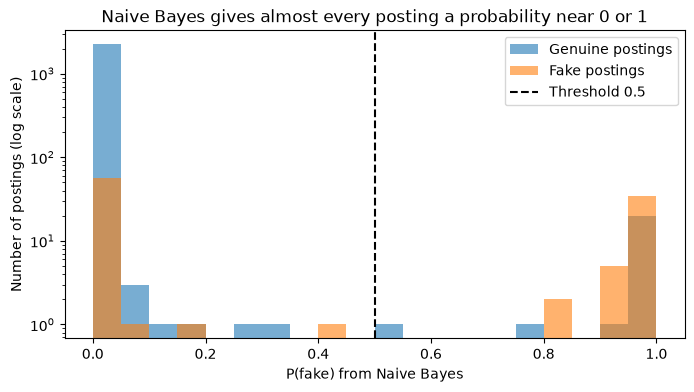

Postings with P(fake) below 0.01 or above 0.99: 98.6%
Fake postings with P(fake) below 0.01 (confidently missed): 55 of 101


In [24]:
# --- VISUALISATION 1: HOW CONFIDENT IS NAIVE BAYES? ---

is_fake_val = (val[LABEL] == 1).to_numpy()
real_probs = val_probs[~is_fake_val]
fake_probs = val_probs[is_fake_val]

plt.figure(figsize=(8, 4))
plt.hist(real_probs, bins=20, alpha=0.6, label="Genuine postings")
plt.hist(fake_probs, bins=20, alpha=0.6, label="Fake postings")
plt.axvline(0.5, color="black", linestyle="--", label="Threshold 0.5")
plt.yscale("log")
plt.xlabel("P(fake) from Naive Bayes")
plt.ylabel("Number of postings (log scale)")
plt.title("Naive Bayes gives almost every posting a probability near 0 or 1")
plt.legend()
plt.show()

extreme = (val_probs < 0.01) | (val_probs > 0.99)
print(f"Postings with P(fake) below 0.01 or above 0.99: {extreme.mean():.1%}")
print(f"Fake postings with P(fake) below 0.01 (confidently missed): {(fake_probs < 0.01).sum()} of {len(fake_probs)}")

*Figure 1: Naive Bayes probabilities on validation (genuine vs fake).*

Almost every posting is pushed to one end of the scale where 98.6% of postings get P(fake) below 0.01 or above 0.99, and very few fall in between. 55 of the 101 fake postings get P(fake) below 0.01, so the model is confidently wrong about more than half of the scams, and no threshold can catch them. This confirms that Naive Bayes is overconfident, because it treats every word as an independent evidence, so a long posting builds up a very large score in one direction. Thats why I combine P(fake) with red flag features in the risk score instead of relying on it alone.

### Visualisation 2

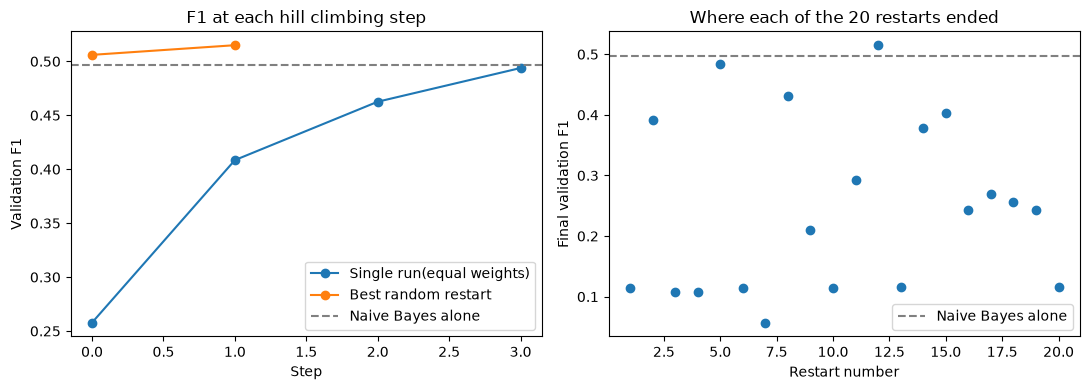

In [25]:
# --- VISUALISATION 2: HILL CLIMBING ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(f1_log, marker="o", label="Single run(equal weights)")
ax1.plot(best_log, marker="o", label="Best random restart")
ax1.axhline(0.497, color="grey", linestyle="--", label="Naive Bayes alone")
ax1.set_xlabel("Step")
ax1.set_ylabel("Validation F1")
ax1.set_title("F1 at each hill climbing step")
ax1.legend()

ax2.plot(range(1, len(restart_f1s) + 1), restart_f1s, "o")
ax2.axhline(0.497, color="grey", linestyle="--", label="Naive Bayes alone")
ax2.set_xlabel("Restart number")
ax2.set_ylabel("Final validation F1")
ax2.set_title("Where each of the 20 restarts ended")
ax2.legend()

plt.tight_layout()
plt.show()

*Figure 2: Hill climbing F1 per step (left) and final F1 of each random restart (right).*

F1 only ever goes up during a run and stops when no neighbour is better. The single run from equal weights stops after 3 steps, just below Naive Bayes. The final F1 values of the restarts are widely spread, from 0.057 to 0.515, and only one ends above the Naive Bayes line. This shows the search often gets stuck at a poor local maximum, so random restarts were needed to find a better solution.

### Fairness

**Fairness check**

In [26]:
# --- FAIRNESS CHECK: FALSE ALARMS WITH vs WITHOUT A LOGO (validation) ---
genuine = val[LABEL].to_numpy() == 0
has_logo = val["has_company_logo"].to_numpy() == 1

models = {"No-logo rule": no_logo_baseline(val), "Naive Bayes": val_pred, "Final system": val_best_pred}
for name, pred in models.items():
    with_logo = pred[genuine & has_logo].mean()
    without_logo = pred[genuine & ~has_logo].mean()
    gap = abs(without_logo - with_logo) * 100
    print(f"{name}: {with_logo:.1%} with logo vs {without_logo:.1%} without logo (gap {gap:.1f} points)")

No-logo rule: 0.0% with logo vs 100.0% without logo (gap 100.0 points)
Naive Bayes: 1.0% with logo vs 1.0% without logo (gap 0.0 points)
Final system: 1.0% with logo vs 1.0% without logo (gap 0.0 points)


Among genuine postings, I compared how often each model wrongly flags companies with and without a logo. The no-logo rule flags every genuine company without a logo (100%) and none with one, a 100-point gap, so it unfairly punishes small or new employers who simply have no logo. Naive Bayes and the final system wrongly flag about 1% of genuine postings in both groups, a gap close to 0 points, which meets my H1 target of under 10 points. Even though "no logo" is one of the red flags, its small weight (0.14) means it cannot cause a flag on its own, so the final system catches scams without unfairly targeting employers that lack a logo.

### Final evaluation (test set)

All design choices were made on the validation set. I will now run every model once on the untouched test set which contains 101 fake postings out of 2368. These numbers are my final results, and I do not change anything after seeing them.

In [27]:
# --- FINAL EVALUATION ON THE TEST SET ---
test_probs = []
for tokens in test["tokens"]:
    test_probs.append(prob_fake(tokens, nb))
test_probs = np.array(test_probs)

X_test = np.column_stack([test_probs, test["no_logo"], test["no_questions"], test["payment_term"]])
y_test = test[LABEL]
final_w = np.array(best_state[:4])
final_b = best_state[4]
test_final_pred = classify_all(X_test, final_w, final_b)

test_models = [
    ("Majority class (always genuine)", majority_baseline(test)),
    ("Keyword rule", keyword_baseline(test)),
    ("No logo rule", no_logo_baseline(test)),
    ("Naive Bayes (threshold=0.5)", (test_probs >= 0.5).astype(int)),
    ("Final system", test_final_pred),
]

rows = []
for name, pred in test_models:
    rows.append({"model": name, **evaluate(y_test, pred)})
test_results = pd.DataFrame(rows).set_index("model").round(3)
test_results

,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority class (always genuine),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,2,14,99,2253,0.952,0.125,0.020,0.034
No logo rule,72,413,29,1854,0.813,0.148,0.713,0.246
Naive Bayes (threshold=0.5),23,21,78,2246,0.958,0.523,0.228,0.317
Final system,24,24,77,2243,0.957,0.500,0.238,0.322


On the untouched test set, the final system catches 24 of 101 scams with 24 false alarms (recall 0.238, precision 0.500, F1 0.322). It has the best F1 of any model, ahead of the no-logo rule (0.246), but it is only one scam better than Naive Bayes alone (F1 0.317), so the small gain from the red flags on validation did not hold. Scores are clearly lower than on validation (F1 0.515). There are likely three reasons: each split has only 101 scams, so results vary a lot between splits; validation was used for several choices, including picking the best of 20 restarts, which makes its scores optimistic; and the model relies on source-specific words that do not generalise.

**Check the H1 targets**

In [28]:
# --- H1 TARGETS (test set) ---
final = test_results.loc["Final system"]
print(f"Recall {final['recall']:.3f} (target 0.80) ->", "met" if final["recall"] >= 0.80 else "not met")
print(f"F1 {final['f1']:.3f} (target 0.65) ->", "met" if final["f1"] >= 0.65 else "not met")

Recall 0.238 (target 0.80) -> not met
F1 0.322 (target 0.65) -> not met


Neither performance target from H1 is met (recall 0.238 vs 0.80, F1 0.322 vs 0.65). In hindsight these targets were optimistic: even on validation, no setting reached 0.80 recall without hundreds of false alarms, because Naive Bayes is confidently wrong about most scams. I report the targets as set in H1 rather than lowering them after seeing the results.

**Visualization 3.** Comparison chart

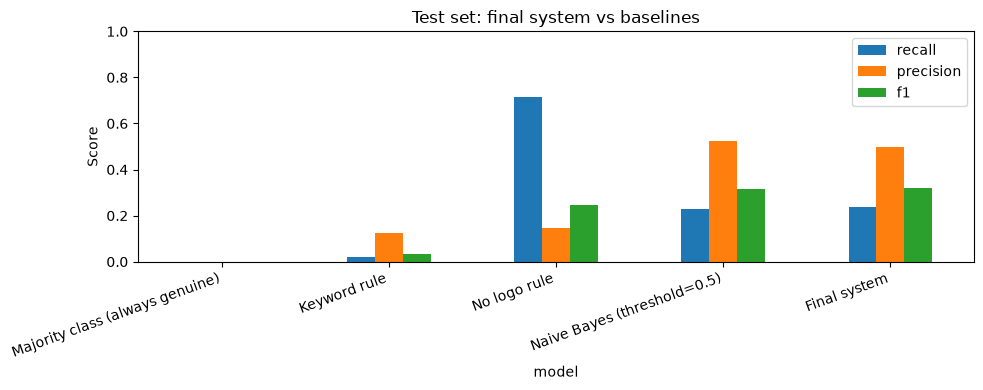

In [29]:
# --- VISUALISATION 3: FINAL COMPARISON ---
chart_data = test_results[["recall", "precision", "f1"]]   # table built in tomorrow's test-set cell

chart_data.plot(kind="bar", figsize=(10, 4))
#plt.axhline(0.80, color="red", linestyle=":", label="H1 recall target (0.80)")
#plt.axhline(0.65, color="grey", linestyle="--", label="H1 F1 target (0.65)")
plt.ylabel("Score")
plt.title("Test set: final system vs baselines")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

*Figure 3: Test-set comparison of all models against the H1 targets.*

**Fairness check** on test set

In [30]:
# --- FAIRNESS CHECK (test set) ---

genuine = y_test.to_numpy() == 0
has_logo = test["has_company_logo"].to_numpy() == 1

 # No-logo rule, Naive Bayes, Final system
for name, pred in test_models[2:]:         
    with_logo = pred[genuine & has_logo].mean()
    without_logo = pred[genuine & ~has_logo].mean()
    print(f"{name}: {with_logo:.2%} with logo vs {without_logo:.2%} without logo "
          f"(gap {abs(without_logo - with_logo) * 100:.1f} points)")

No logo rule: 0.00% with logo vs 100.00% without logo (gap 100.0 points)
Naive Bayes (threshold=0.5): 0.86% with logo vs 1.21% without logo (gap 0.3 points)
Final system: 0.92% with logo vs 1.69% without logo (gap 0.8 points)


The fairness result holds on the test set. The final system wrongly flags 0.92% of genuine companies with a logo and 1.69% without one, a gap of 0.8 points, which meets the H1 target of under 10 points. The no-logo rule again has a 100-point gap.

**Failure analysis**

In [31]:
# --- FAILURE ANALYSIS (test set) ---

test_fake = y_test.to_numpy() == 1
missed = test[test_fake & (test_final_pred == 0)]
false_alarms = test[~test_fake & (test_final_pred == 1)]

def show(df, n=10):
    for i in range(min(n, len(df))):
        row = df.iloc[i]
        p = prob_fake(row["tokens"], nb)
        print(f"- {row['title'][:50]} | P(fake)={p:.3f} | words={len(row['tokens'])} | "
              f"no_logo={row['no_logo']} no_q={row['no_questions']} pay={row['payment_term']}")
        print("   top words:", [w for w, _ in explain(row["tokens"], nb, n=3)])

print(f"MISSED SCAMS ({len(missed)} total):")
show(missed)
print(f"\nFALSE ALARMS ({len(false_alarms)} total):")
show(false_alarms)

MISSED SCAMS (77 total):
- Compensation Consultant, Toronto, ON, Canada | P(fake)=0.000 | words=128 | no_logo=1 no_q=0 pay=0
   top words: ['powerpoint', 'word', 'ms']
- Call Center Representative | P(fake)=0.000 | words=85 | no_logo=1 no_q=1 pay=0
   top words: ['rings', 'chats', 'designated']
- Receptionist - Administrative Assistant | P(fake)=0.000 | words=60 | no_logo=1 no_q=0 pay=0
   top words: ['titan', 'eminent', 'administrative']
- Full-time Administrative Assistant. | P(fake)=0.000 | words=91 | no_logo=1 no_q=1 pay=0
   top words: ['administrative', 'entry', 'faxing']
-  SENIOR CORPORATE RECCRUITER | P(fake)=0.000 | words=438 | no_logo=1 no_q=1 pay=0
   top words: ['expro', 'servicesproduction', 'upproductionwell']
- PART-TIME WORK FROM YOUR PLACE | P(fake)=0.006 | words=33 | no_logo=1 no_q=1 pay=0
   top words: ['guaranteed', 'pay', 'per']
- Brand & Logo Design Contest | P(fake)=0.000 | words=129 | no_logo=1 no_q=1 pay=0
   top words: ['belongings', 'contest', 'father']
- Of

Almost every missed scam gets P(fake) = 0.000, so Naive Bayes is confidently wrong. Many are admin, receptionist or call-centre jobs without a logo, but the red-flag weights are too small to flag them without Naive Bayes (no logo + no questions = 0.34, below the 0.49 threshold). Even "PART-TIME WORK FROM YOUR PLACE", which promises "guaranteed pay", was missed (P(fake) = 0.006). False alarms are mostly specialised jobs, such as doctors, engineers and welders, flagged because of place names and rare words ("bahrain", "mechanicsburg", "tattnall"). Two come from the same recruiter, and several are very short (13–28 words), where a few rare words decide the result. Both kinds of error come from the same weakness: the model learns specific sources and words instead of general scam patterns.

**Check a new posting.** This function lets a user paste in a job title and description, plus whether the ad has a logo and screening questions. It returns a verdict, a risk score, and the signals behind the decision, using the official final system.

In [32]:
# --- CHECK A NEW POSTING (official final system) ---
def check_posting(title, description, has_logo, has_questions):
    """Score a new posting and explain the result in plain English."""
    text = title + " " + description

    # Turn real emails, links and phone numbers into the same placeholders the dataset uses
    text = re.sub(r"\S+@\S+", " #EMAIL_x# ", text)
    text = re.sub(r"http\S+|www\.\S+", " #URL_x# ", text)
    text = re.sub(r"\+?\d[\d\-\s]{7,}\d", " #PHONE_x# ", text)

    tokens = tokenise(text)
    p = prob_fake(tokens, nb)
    no_logo = 0 if has_logo else 1
    no_questions = 0 if has_questions else 1
    payment = has_payment_term(tokens)

    x = [p, no_logo, no_questions, payment]
    risk = np.dot(final_w, x)
    verdict = "⚠️ NEEDS REVIEW" if risk + final_b >= 0 else "✅ Looks genuine"

    print(f"Verdict: {verdict}")
    print(f"Risk score: {risk:.2f} (threshold {-final_b:.2f}) | P(fake) from text: {p:.1%}")
    print("Signals found:")
    if no_logo: print("  - No company logo")
    if no_questions: print("  - No screening questions")
    if payment: print("  - Mentions a payment word")
    if "emailtoken" in tokens: print("  - Email address in the text (moves contact off the job site)")
    if "phonetoken" in tokens: print("  - Phone number in the text (moves contact off the job site)")
    if "urltoken" in tokens: print("  - Link in the text")
    print("  - Most suspicious words:", [w for w, _ in explain(tokens, nb, n=5)])

# Try it on a made-up suspicious posting and a normal one
check_posting(
    "URGENT!!! DATA ENTRY WORK FROM HOME",
    "Earn money fast! No experience needed. Weekly pay $2500. Contact hr.recruit2024@gmail.com "
    "or 555-018-7742 to start immediately!!!",
    has_logo=False, has_questions=False)
print()
check_posting(
    "Junior Software Engineer",
    "Our team builds payment systems for banks. You will write and test Python code, "
    "review pull requests and work with senior engineers in an agile team.",
    has_logo=True, has_questions=True)

Verdict: ⚠️ NEEDS REVIEW
Risk score: 1.18 (threshold 0.49) | P(fake) from text: 90.9%
Signals found:
  - No company logo
  - No screening questions
  - Email address in the text (moves contact off the job site)
  - Phone number in the text (moves contact off the job site)
  - Most suspicious words: ['earn', 'entry', 'phonetoken', 'immediately', 'pay']

Verdict: ✅ Looks genuine
Risk score: 0.05 (threshold 0.49) | P(fake) from text: 0.0%
Signals found:
  - Mentions a payment word
  - Most suspicious words: ['systems', 'test', 'review', 'work', 'pull']


The made-up scam posting is rated "needs review" with P(fake) = 90.9% and a risk score of 1.18, well above the 0.49 threshold. It triggers four signals: no logo, no screening questions, an email address and a phone number, and its most suspicious words ("earn", "entry", "immediately", "pay") match common scam language. The normal software engineering posting is rated genuine with P(fake) = 0.0%. It still triggers the payment-word flag, because it mentions "payment systems for banks", which shows that a simple word flag cannot tell asking for a fee apart from working in the payments industry. Its small weight means it did not change the decision. This shows how a job seeker could use Job Guard: paste in an ad and see both a verdict and the reasons behind it. Because the model was trained on old, mostly US postings, a result should prompt the user to check the ad, not be treated as a final answer.

### Second test run

**Second test run (after seeing the first results).** After the first test run, the failure analysis showed that most missed scams had P(fake) = 0.000. I tested length normalisation on validation (Experiment 3) and it met my pre-set rule, so I run the test set a second time with this version. Because this choice was made after seeing the first test results, the first run remains the official result. This run shows whether the fix carries over to unseen data.

In [33]:
# --- SECOND TEST RUN: NORMALISED NB + RISK SCORE ---
test_probs_norm = []
for tokens in test["tokens"]:
    test_probs_norm.append(prob_fake_norm(tokens, nb))
test_probs_norm = np.array(test_probs_norm)

X_test_norm = np.column_stack([test_probs_norm, test["no_logo"], test["no_questions"], test["payment_term"]])
test_norm_pred = classify_all(X_test_norm, np.array(best_state_n[:4]), best_state_n[4])

test_results = add_result(test_results, "Exp 3 system (second run)", y_test, test_norm_pred)
display(test_results)

# fairness check for the new system
with_logo = test_norm_pred[genuine & has_logo].mean()
without_logo = test_norm_pred[genuine & ~has_logo].mean()
print(f"Exp 3 system: {with_logo:.2%} with logo vs {without_logo:.2%} without logo "
      f"(gap {abs(without_logo - with_logo) * 100:.1f} points)")

,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
Majority class (always genuine),0,0,101,2267,0.957,0.000,0.000,0.000
Keyword rule,2,14,99,2253,0.952,0.125,0.020,0.034
No logo rule,72,413,29,1854,0.813,0.148,0.713,0.246
Naive Bayes (threshold=0.5),23,21,78,2246,0.958,0.523,0.228,0.317
Final system,24,24,77,2243,0.957,0.500,0.238,0.322
Exp 3 system (second run),35,47,66,2220,0.952,0.427,0.347,0.383


Exp 3 system: 0.97% with logo vs 7.02% without logo (gap 6.1 points)


On the second test run, the length-normalised system caught 35 of 101 scams (recall 0.347) compared with 24 in the first run, and F1 rose from 0.322 to 0.383, the best of any model on the test set. The fix for overconfidence therefore carried over to unseen data, confirming that it was a major cause of missed scams. The gain came at a cost: false alarms rose from 24 to 47, and the fairness gap grew from 0.8 to 6.1 points (0.97% with a logo vs 7.02% without), still within my H1 target of 10 points. Since the logo weight is only 0.04, this gap comes from the text model itself: genuine postings from companies without a logo appear to use wording closer to scams. Neither performance target is met, and scores remain lower than on validation (F1 0.536), so the remaining errors come from the model relying on source-specific words. Because this version was chosen after seeing the first test results, the first run remains my official result. This run shows the direction of improvement.

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

I built Job Guard, a system that reads a job posting and decides whether it should be flagged as a possible scam, along with the main reasons why. It was trained and tested on the Real/Fake Job Posting Prediction dataset where there are 15,787 postings after removing duplicates, and 4.26% of them which are fake.

Fake job ads are written to look real, but their aim is to collect personal details, bank information or "processing fees". Students and fresh graduates are affeced the most, because they are inexperienced and eager to find work. A tool that flags suspicious ads, and explains why, could stop people before they share anything.

The warning signs are not very clear and spread across many words, so simple rules do not work. A fixed list of 15 common scam phrases caught only 1 of 101 scams on my validation set, and a "no company logo" rule caught more but wrongly flagged 399 genuine ads. A model that learns from thousands of labelled examples can pick up patterns no one would think to write down. AI also lets me measure the trade-off between catching scams and false alarms, and tune it directly.

### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

I used three techniques taught in this unit in one pipeline: a Multinomial Naive Bayes classifier that gives each posting a probability of being fake, a weighted sum that combines this probability with three red flags which are no logo, no screening questions, and payment words, and hill climbing to choose the weights and threshold.

**How did I adapt or extend them?**
- **Naive Bayes:** instead of only checking whether a word appears, I count how often it appears (multinomial). I added Laplace smoothing so unseen words do not make the probability zero, and used log probabilities so long postings do not create numbers too small to store. I also turned links, emails and phone numbers into single tokens, since scams use them more often.
- **Weighted sum:** I used it as a risk score. A posting is flagged if w·x + b ≥ 0, where x holds P(fake) and the three flags.
- **Hill climbing:** I used it to maximise validation F1 instead of minimising conflicts. When one run got stuck, I added 20 random restarts.
- **Experiment 3:** after finding that Naive Bayes was overconfident, I divided its score by the number of words which is also known as length normalisation.

**What design decisions did I make and why?**
- **Removed 2,093 duplicates,** so the same posting could not appear in both training and testing and affect the results.
- **Stratified 70/15/15 split,** so each part keeps the same share of fake postings, because with only 101 scams per split, a random split could change the results by chance.
- **Recall and F1 instead of accuracy,** because accuracy is about 96% even for a model that catches nothing.
- **Hill climbing over gradient descent,** because F1 changes in jumps, so there is no smooth gradient to follow.
- **Test set used only at the end,** so my final results are honest.

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

**What worked?**
- **Naive Bayes was much better than simple rules.** On validation it reached F1 0.497, double the best baseline (no-logo rule, 0.233), with only 23 false alarms instead of 399.
- **Random restarts fixed the stuck search.** The best of 20 restarts reached F1 0.515, beating Naive Bayes alone.
- **Fairness held.** On the test set, my official system wrongly flagged genuine companies with and without a logo at almost the same rate (a 0.8-point gap), meeting my H1 target of under 10 points.
- **Length normalisation (Experiment 3) worked.** On a second, clearly labelled test run, it caught 35 scams instead of 24 and raised F1 from 0.322 to 0.383.

**What didn't work?**
- **I missed both performance targets.** On the test set, the official system caught only 24 of 101 scams (recall 0.238, F1 0.322, against targets of 0.80 and 0.65). I was too overconfident on my target recall and F1 during H1 planning.
- **Lowering the threshold barely helped.** Going from 0.5 to 0.01 only caught 5 more scams.
- **Scores dropped from validation to test** (F1 0.515 to 0.322), partly because each split has only 101 scams, and because picking the best of 20 runs on validation made validation look better than it really was.

**What do the visualisations show?**
- **Figure 1** shows that 98.6% of postings get P(fake) near 0 or 1, and 55 scams were given almost zero. This explains why the threshold made little difference.
- **Figure 2** shows that the 20 restarts ended anywhere from 0.057 to 0.515, so the search has many local maxima, like the 8-queens problem.
- **Figure 3** compares all models on the test set against my targets.

**How did performance change across experiments?**
- **Experiment 1:** removing rare words lowered F1 (0.497 to 0.360).
- **Experiment 2:** random restarts raised F1 (0.494 to 0.515).
- **Experiment 3:** length normalisation raised F1 again (0.515 to 0.536 on validation, and 0.322 to 0.383 on test).

**What was surprising?**
- **Removing rare words made things worse.** Most rare words come from genuine postings, so they had been helping the model recognise genuine ads.
- **The red flags barely mattered in the end.** After normalisation, hill climbing gave them almost no weight.
- **The model learned places, not scams.** Many flags were triggered by words like "bakersfield" and "mechanicsburg".
- **Catching more scams made fairness worse.** Experiment 3 widened the logo gap from 0.8 to 6.1 points.

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

**Where does my approach fail?**
- **Confident misses:** most missed scams got P(fake) = 0.000, so the red flags could not rescue them.
- **Wrong reasons:** many flags came from place names or specific recruiters, such as "bahrain" and "mechanicsburg", not real scam signs.
- **Short postings:** in ads of only 13–28 words, one or two rare words decided the result.
- **Simple word flags:** the payment flag fired on a genuine job about "payment systems for banks".

**What assumptions are violated?**
- **Naive Bayes assumes words are independent.** In reality they are not, so on long postings the evidence adds up far too quickly and the model becomes overconfident.
- **I assumed new scams look like old ones.** The data is old and mostly from the US, and scammers change their wording, so the model may not work on current or Malaysian ads.
- **I assumed 101 scams per split was enough.** Results changed a lot between validation and test (F1 0.515 vs 0.322).

**What would I do with more time?**
- Keep length normalisation and remove place and company names before training.
- Fix the text cleaning so joined words like "accountsperform" are split properly.
- Use cross-validation for more stable results.
- Try logistic regression trained with gradient descent, so words and red flags are learned together.

### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

**Who is affected?** Job seekers, especially students and fresh graduates, could lose money or personal data if a scam is missed. Honest employers, especially small companies, could lose applicants if their ads are wrongly flagged.

**Which failure modes matter most?** Missed scams cause the most direct harm, because the job seeker trusts an ad the system called safe. My official system still missed 77 of 101 scams. Wrongly flagging small employers also matters, because that harm falls unfairly on one group.

**C2: Fairness across groups.** A model can look fair overall but still make more mistakes for one group, so I checked false alarms separately for genuine companies with and without a logo. The no-logo rule wrongly flags every genuine company without a logo and none with one. My system kept the difference to 0.8 percentage points. But when I ran Experiment 3 caught more scams, companies without a logo were wrongly flagged 7.02% of the time, compared with 0.97% for those with one. Protecting more job seekers made the system less fair to small employers, and deciding which matters more is a value judgement, not just a technical one.

**C4: Distribution shift and model cards.** Scammers keep changing their wording, so like the spam filter in C4, performance would drop on new scams. A model card should state that Job Guard only marks ads as "needs review", was trained on old, mostly US data, and needs ongoing monitoring.

### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

I used an AI assistant (Dia) to plan my daily tasks, explain concepts I was unsure about, draft code that I then tested and edited, and help word my notes and report.

**What did I accept?**
- Laplace smoothing, log probabilities and the stratified split, after checking them against small examples I worked out by hand.
- Removing 2,093 duplicate postings before splitting, so test results would not be inflated.
- Random restarts for hill climbing and length normalisation for Naive Bayes, which I kept only after they improved my validation results.

**What did I reject, and why?**
- The AI first used five text columns. I changed this to title and description to match my approved H1 scope.
- I replaced its more complex code (regex keyword matching and its first hill climbing version) with simpler versions in the style taught in P4, P7 and P8, so I could explain every line.
- I fixed AI mistakes I found: a wrong expected test result, a missing `import math`, and code that caused a pandas warning. I also corrected it when it misread my library versions from a screenshot.
- I rejected its first report drafts because they did not answer each question directly, and I replaced a fairness concept I could not explain clearly with one I understood.
- The AI advised against further tuning after the first test run. I chose to try length normalisation anyway, but tested it on validation first and kept my first test run as the official result.

---

## Submission Checklist

- [x] Recap of H1 scope (and any pivot) at the top
- [x] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [x] Project report (~1500 words) covering all 6 sections
- [x] Implementation demonstrates HD-level depth beyond earlier task work
- [x] Ethical reflection connects to C2 or C4
- [x] AI use statement shows critical evaluation
- [x] Code is readable, reproducible, documented
- [x] Uploaded to OnTrack and marked **Ready for Feedback**
- [x] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*